#**Many Artificial LSST Lightcurves based on Observations of Real Nuclear Transients (MALLORN) - Data Production Notebook** #

This notebook details the process of going from an existing 2-band Zwicky Transient Facility (ZTF) lightcurve to a simulated 6-band Legacy Survey of Space and Time (LSST) lightcurve with realistic cadence and luminosity. Therefore providing more context as to how the MALLORN data set was produced. Each cell outlines a separate stage in the production of a simulated LSST lightcurve. This is a simplification of the overall process, with a specially chosen object and parameters to produce clear lightcurves. The actual process involves various additional parameters and checks which are not included in this notebook to protect the integrity of the MALLORN Classifier Challenge.

A lightcurve displays the change in observed luminosity over time for a specific object. For most transients, this consists of a quick rise to peak followed by a slower decline back to the baseline. The luminosity is different depending on the wavelength of light you are observing. We observe using different filters to get different wavelength bands of light, which allows us to know more about the colour evolution of the object and can be very useful for photometric classification. ZTF observed in two bands (g, r), whilst LSST will observe in six (u, g, r, i, z, y).

The methods employed here to produce a simulated LSST lightcurve from an existing ZTF lightcurve should be straightforward to replicate to produce simulated data for any other future telescope/survey - provided that you have the limiting magnitudes for the relevant instrument and the cadence of observations. Therefore, the below code could easily be adapted for other purposes in the future. If that is of interest to you, please contact the author - Dylan Magill (dmagill14@qub.ac.uk) - for more information on the methodology and functionalities of this approach.

**Step One: Loading the real ZTF Data**

In [ ]:
#Run this the first time to set up the necessary packages in the Google Colab Notebook

# !pip install numpy==1.26.4
# !pip install pandas==2.3.0
# !pip install scikit-learn==1.7.0
# !pip install astropy==7.1.0
!pip install dustmaps==1.0.14
!pip install extinction==0.4.7
!pip install skyfield==1.53
!pip install skyproj==2.1.0
!pip install smmap==5.0.2
!pip install sncosmo==2.12.1
!pip install rubin-sim==2.2.4
!pip install rubin-scheduler==3.8.0
!pip install gdown

In [ ]:
#Run this the first time to set up the necessary files in the Google Colab Notebook

import pathlib
import os

data_dir = '/content/rubin_sim_data/'
code_dir = '/content'

pathlib.Path(data_dir).mkdir(parents=True, exist_ok=True)

utils_dir = '/content/rubin_sim_data/utils'
pathlib.Path(utils_dir).mkdir(parents=True, exist_ok=True)

files_to_download = {
    os.path.join(data_dir, "baseline_v5.0.0_10yrs.db"): "157orDlMygHTbcvi_G76R0PBFAw5Pp_xp",
    os.path.join(data_dir, "ZTF22abcfics_clean_data.txt"): "1cay7qhZ3zqc7w2kyjebPts8lDz-sOcqE",
    os.path.join(utils_dir, "fov_map.npz"): "1y8jZ_9WppbB3Ik0pm5JoXHJQ1uu4nswl",
    os.path.join(code_dir, "bsline_crctn.py"): "1mYOEO5ojFVVFGwV4HPhXyVp0OyfmeIHs"}

for fpath, fid in files_to_download.items():
    url = f"https://drive.google.com/uc?id={fid}"
    if not os.path.exists(fpath):
        print(f"Downloading {os.path.basename(fpath)}...")
        !gdown "{url}" -O "{fpath}"
    else:
        print(f"{os.path.basename(fpath)} already exists, skipping.")

os.environ['RUBIN_SIM_DATA_DIR'] = '/content/rubin_sim_data'

import sys
if code_dir not in sys.path:
    sys.path.append(code_dir)

print("\n\nSetup complete. Available files:")
!ls -lh /content
!ls -lh /content/rubin_sim_data


baseline_v5.0.0_10yrs.db already exists, skipping.
ZTF22abcfics_clean_data.txt already exists, skipping.
fov_map.npz already exists, skipping.
bsline_crctn.py already exists, skipping.


Setup complete. Available files:
total 20K
-rw-r--r-- 1 root root 3.5K Aug 19 09:07 bsline_crctn.py
drwxr-xr-x 2 root root 4.0K Oct 13 21:49 __pycache__
drwxr-xr-x 3 root root 4.0K Oct 13 21:49 rubin_sim_data
drwxr-xr-x 1 root root 4.0K Oct 10 13:36 sample_data
drwxr-xr-x 2 root root 4.0K Oct 13 23:00 temp
total 728M
-rw-r--r-- 1 root root 728M Oct 13 09:44 baseline_v5.0.0_10yrs.db
drwxr-xr-x 2 root root 4.0K Oct 13 21:49 utils
-rw-r--r-- 1 root root  77K Aug 19 09:07 ZTF22abcfics_clean_data.txt


In [ ]:
# 1.1: Importing packages

#Importing the necessary packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn.gaussian_process as gp
from sklearn.gaussian_process.kernels import Matern, WhiteKernel, ConstantKernel as C
from astropy.coordinates import SkyCoord, Distance
from dustmaps.sfd import SFDQuery
import dustmaps.sfd
import extinction
from extinction import fitzpatrick99
from dustmaps.config import config
import sncosmo
from astropy.cosmology import WMAP9
import astropy.units as u
from astropy.cosmology import z_at_value
import os
import rubin_sim.maf as maf
import rubin_scheduler.utils as rsUtils

#Defining filter colours for later plots
filter_colours = {'u': '#6A5ACD', 'g': '#2ca02c', 'r': '#d62728', 'i': '#ff7f0e', 'z': '#8c564b', 'y': '#1b1b1b'}

In [ ]:
# 1.2: Loading in the ZTF lightcurve

#Set the path to the chosen object - ZTF22abcfics - a Type II supernova
path = '/content/rubin_sim_data/ZTF22abcfics_clean_data.txt'

#Assigning names for each column of the ZTF lightcurve csv file
cols = ['time_jd', 'flux', 'flux_unc', 'zeropt', 'filter']

#Reading in the text file for the ZTF lightcurve
df = pd.read_csv(path, sep=r"\s+", skiprows=3,names=cols, usecols=cols)

In [ ]:
# 1.3: Separating r band & g band data

#Using mask to define r band data and saving to respective arrays
r_mask = df['filter'] == 'ZTF_r'
r_time = np.array(df.loc[r_mask, 'time_jd'])
r_flux = np.array(df.loc[r_mask, 'flux'])
r_error = np.array(df.loc[r_mask, 'flux_unc'])
r_zpt_list = df.loc[r_mask, 'zeropt'].tolist()

#Using mask to define g band data and saving to respective arrays
g_mask = df['filter'] == 'ZTF_g'
g_time = np.array(df.loc[g_mask, 'time_jd'])
g_flux = np.array(df.loc[g_mask, 'flux'])
g_error = np.array(df.loc[g_mask, 'flux_unc'])
g_zpt_list = df.loc[g_mask, 'zeropt'].tolist()

In [ ]:
# 1.4: Defining functions to convert between magnitudes and fluxes

#Defining a function to convert from AB magnitude to flux in microjanskys
def ab_to_uJy (magAB):
    flux_Jy = 10**(23 - (magAB + 48.6)/2.5)
    flux_mJy = flux_Jy*1000000
    return flux_mJy

#Defining a function to convert from flux in microjanskys to AB magnitude
def uJy_to_ab (mJy):
    flux_Jy = mJy/1000000
    ab = 2.5*(23 - np.log10(flux_Jy))-48.6
    return ab

In [ ]:
# 1.5: Converting to flux and applying baseline correction to data

#Importing baseline correction function
from bsline_crctn import inverse_variance_weighting
from bsline_crctn import baseline_correction_4filter

#Determining zeropoint values and converting flux from digital number (DN) to flux in uJy
r_zpt = np.mean(r_zpt_list)
r_flux = r_flux * ab_to_uJy(r_zpt)
r_error = r_error * ab_to_uJy(r_zpt)

#Determining peak and peak time
r_peak = max(r_flux)
r_peak_time = r_time[np.argmax(r_flux)]

#Applying baseline correction to the r band data
r_flux, r_error, r_crctn_data, bl_flag = baseline_correction_4filter(r_flux, r_error, r_time, goback=100, peak_time=r_peak_time)

#Determining zeropoint values and converting flux from digital number (DN) to flux in uJy
g_zpt = np.mean(g_zpt_list)
g_flux = g_flux * ab_to_uJy(g_zpt)
g_error = g_error * ab_to_uJy(g_zpt)

#Determining peak and peak time
g_peak = max(g_flux)
g_peak_time = g_time[np.argmax(g_flux)]

#Applying baseline correction to the g band data
g_flux, g_error, g_crctn_data, bl_flag = baseline_correction_4filter(g_flux, g_error, g_time, goback=100, peak_time=r_peak_time)

In [ ]:
# 1.6: Defining object position and calculating extinction coefficient value

#Importing necessary packages
from astropy.coordinates import SkyCoord, Distance
from dustmaps.sfd import SFDQuery
import dustmaps.sfd
import extinction
from extinction import fitzpatrick99
from dustmaps.config import config

#Loading in relevant dustmap
from dustmaps.config import config
config['data_dir'] = '/path/to/data/directory'
config.reset()
dustmaps.sfd.fetch()

#Defining the Right Ascension (RA) and Declination (Dec) of the object. These indicate the position of the object in the night sky. Sourced from Transient Name Server.
obj_RA = 274; obj_Dec = 14

#Defining the redshift of the object. Sourced from the Transient Name Server.
redshift = 0.03

#Calculating the extinction coefficient value, E(B-V), for the position of the chosen object using the Schlafly & Finklebeiner (2011) SFD dust map
ZTF_coords = SkyCoord(obj_RA,obj_Dec, unit='deg')
SFD = SFDQuery()
ebv = SFD(ZTF_coords) * 0.86

Checking existing file to see if MD5 sum matches ...
File exists. Not overwriting.
Checking existing file to see if MD5 sum matches ...
File exists. Not overwriting.


In [ ]:
# 1.7: Defining a function to de-extinct the flux values

#Defining function to de-extinct a set of flux values
def jurassic_park (flux, eff_wl):
    A_lambda = fitzpatrick99(eff_wl, ebv * 3.1) #3.1 = Standard Milky Way value
    flux_ext = flux * 10**((A_lambda)/2.5)
    return flux_ext, A_lambda

g-band Extinction value = [0.38398177]
r-band Extinction value = [0.25400597]


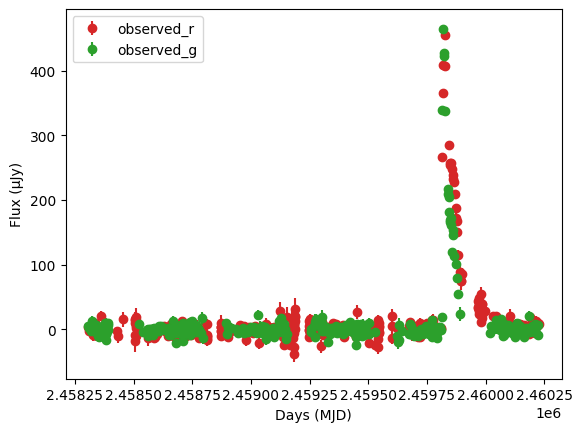

In [ ]:
# 1.8: De-extincting the g band & r band data

#Effective wavelength for each band - sourced from SVO Filter Profile Service for Palomar-ZTF
g_eff_wl_ztf = np.array([4746]); r_eff_wl_ztf = np.array([6366])

#De-extincting ZTF lightcurves
g_flux, g_A_lambda = jurassic_park(g_flux,g_eff_wl_ztf); print(f'g-band Extinction value = {g_A_lambda}')
r_flux, r_A_lambda = jurassic_park(r_flux,r_eff_wl_ztf); print(f'r-band Extinction value = {r_A_lambda}')

#Plotting against the real de-extincted ZTF lightcurve
plt.errorbar(r_time, r_flux, yerr = r_error, label = 'observed_r', color = filter_colours['r'], fmt= 'o')
plt.errorbar(g_time, g_flux, yerr = g_error, label = 'observed_g', color = filter_colours['g'], fmt= 'o')
plt.xlabel('Days (MJD)')
plt.ylabel('Flux (μJy)')
plt.legend()
plt.show()

**Step Two: Applying a Gaussian Process (GP) Fit to the Lightcurve**

In [ ]:
# 2.1: Determining which band has more data points - and hence which to fit with a Gaussian Process

#Defining the amount of r band & g band data points
r_size = len(r_flux); g_size = len(g_flux)
print(f'r-band data points = {r_size}')
print(f'g-band data points = {g_size}')

#Selecting r band if it has more data points than the g band
if r_size > g_size:
    main_band_flux = r_flux
    main_band_time = r_time
    main_band_error = r_error
    main_band_tag = 'r'
    print("r Band Selected")

    #Defining the peak values and times
    main_band_peak = max(main_band_flux)
    main_band_peak_time = main_band_time[np.argmax(main_band_flux)]

    #Setting time relative to peak date
    main_band_time = np.array(main_band_time) - main_band_peak_time
    init_main_band_peak_time = main_band_peak_time
    main_band_peak_time = 0
else:
    #Selecting g band if it has more data points than the r band
    main_band_flux = g_flux
    main_band_time = g_time
    main_band_error = g_error
    main_band_tag = 'g'
    print("g Band Selected")

    #Defining the peak value and time
    main_band_peak = max(main_band_flux)
    main_band_peak_time = main_band_time[np.argmax(main_band_flux)]

    #Setting time relative to peak date
    main_band_time = np.array(main_band_time) - main_band_peak_time
    init_main_band_peak_time = main_band_peak_time
    main_band_peak_time = 0

r-band data points = 838
g-band data points = 381
r Band Selected


In [ ]:
# 2.2: Defining function for Gaussian Process (GP) fit

#Importing necessary packages
import sklearn.gaussian_process as gp
from sklearn.gaussian_process.kernels import Matern, WhiteKernel, ConstantKernel as C

#Defining function for GP fit to a lightcurve
def gp_lc_fit (flux, time, error, peak, max_gp_retries = 4, threshold_ratio = 0.89):

        #Setting length scale
        ls_gp_base = round(len(flux)/40)

        #Adjusting format of errors to work in gp fit
        errs_gp = np.array(error)

        #Setting placeholder best peak ratio value
        best_gp_peak_ratio = 0

        #Setting initial values for best parameters
        best_ls = ls_gp_base
        best_errs = errs_gp

        for attempt in range(max_gp_retries):

            #Creating guess values to allow for variation between runs
            ls_guess = ls_gp_base * np.random.uniform(0.7,1.2)
            noise_guess = np.random.uniform(0.01,0.1)
            amplitude_guess = peak * np.random.uniform(0.8, 1.2)

            #Chooses best parameters for final attempt
            if (attempt + 1) == max_gp_retries:
                ls_gp_base = best_ls
                errs_gp = best_errs

            #Creating kernel and model for main band - reducing error values in order to capture peak
            kernel = C(amplitude_guess, (peak*0.01, peak*100)) * Matern(length_scale=ls_guess, length_scale_bounds=(1e-3, 1e3), nu=3/2) + WhiteKernel(noise_level=noise_guess, noise_level_bounds=(1e-6,1e3))
            model_gp = gp.GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=15, alpha=(errs_gp * 0.9)**2, normalize_y=False)

            #Fitting model for main band
            model_gp.fit(np.array([time]).T,flux)
            params_gp = model_gp.kernel_.get_params()

            #Creating model values for main band
            gp_timescale = np.linspace(min(time), max(time), 1000)
            gp_flux, std_gp = model_gp.predict(np.array([gp_timescale]).T, return_std=True)

            #Determining ratio between GP peak and observed peak
            gp_max_flux = np.max(gp_flux)
            peak_ratio = gp_max_flux/peak
            print('GP Peak / Obs Peak = ',peak_ratio)

            #Breaking if GP model successfully captures the peak
            if gp_max_flux >= threshold_ratio * peak:
                print(f'GP Model Created (attempt {attempt + 1}) - peak captured')
                mse_success_tag = True
                break
            else:
                #Saving values if better than previous run. Best values used for final run.
                if peak_ratio > best_gp_peak_ratio:
                    best_ls = ls_guess
                    best_errs = errs_gp
                #Adjusting values for next attempt at GP fit
                ls_gp_base *= 0.5
                errs_gp *= 0.7
                print(f'GP fit attempt {attempt + 1} failed to reach peak. Retrying fit...')

        return gp_flux, gp_timescale, attempt

GP Peak / Obs Peak =  0.9925511901247335
GP Model Created (attempt 1) - peak captured


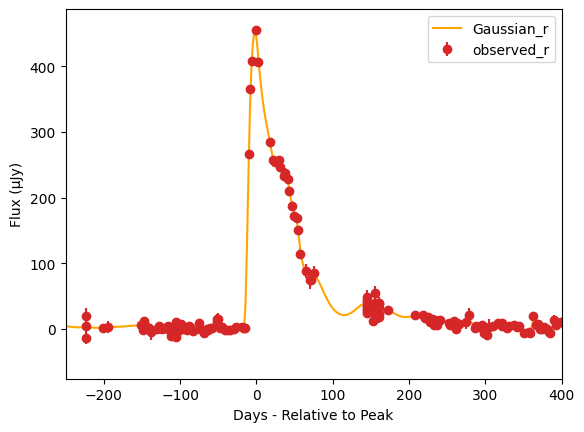

In [ ]:
# 2.3: Applying GP fit to real ZTF lightcurve of chosen band

#Carrying out GP fit for the main band
main_band_flux_gp, gp_timescale, main_band_attempt = gp_lc_fit (main_band_flux, main_band_time, main_band_error, main_band_peak)

#Plotting observed r band data & GP fit of that data
fig1, ax1 = plt.subplots()
ax1.errorbar(main_band_time, main_band_flux, yerr=main_band_error, label='observed_r', color=filter_colours['r'], fmt='o')
ax1.plot(gp_timescale, main_band_flux_gp, label='Gaussian_r', color='orange')
ax1.set_xlabel('Days - Relative to Peak')
ax1.set_ylabel('Flux (μJy)')
ax1.set_xlim(-250,400)
ax1.legend()

**Step Three: Generating data for the other LSST bands**

In [ ]:
# 3.1: Generating SNCosmo spectral energy distribution (SED) models for each band

#Importing necessary package
import sncosmo

#Defining SNCosmo model for chosen object. Specific to each type of object.
model = sncosmo.Model(source='v19-2009ib')
model.set(z=redshift, t0=main_band_peak_time, amplitude=main_band_peak)
spec_tag = 'II'

models = {}
ztf_filters = ['g', 'r']

#Generating SED models for each band that will be observed by LSST
for val in ztf_filters:
    models[val] = model.bandmag('lsst'+val,'ab',time=gp_timescale)

In [ ]:
# 3.2: Determining new redshift for simulated object

#Importing necessary packages
from astropy.cosmology import WMAP9
import astropy.units as u
from astropy.cosmology import z_at_value

#Define ZTF and LSST limiting magnitudes (r-band)
ztf_lim_mag = 20.6
lsst_lim_mag = 24.7

#Converting limiting magnitudes to flux values
ztf_lim_flux = ab_to_uJy(ztf_lim_mag)
lsst_lim_flux = ab_to_uJy(lsst_lim_mag)

#Defining LSST limiting fluxes for each band
u_lim = ab_to_uJy(23.9); g_lim = ab_to_uJy(25.0); r_lim = ab_to_uJy(24.7)
i_lim = ab_to_uJy(24.0); z_lim = ab_to_uJy(23.3); y_lim = ab_to_uJy(22.1)

#Using redshift to calculate the distance to the object
dist_ZTF = Distance(unit=u.pc, z = redshift, cosmology = WMAP9)

#Generating a value to add some random scatter to the simulated distance
dist_scatter = np.random.uniform(0.9,1.2)

#Calculating a simulated distance value that places the object the same amount above the LSST detection limit as the original object was above the ZTF detection limit
dist_LSST = dist_ZTF * np.sqrt(ztf_lim_flux/lsst_lim_flux) * dist_scatter

#Calculate the corresponding redshift for the simulated LSST distance
lsst_redshift = z_at_value(WMAP9.luminosity_distance, dist_LSST)

dilation_factor = (1 + lsst_redshift) / (1 + float(redshift))
gp_timescale_dilated = gp_timescale * dilation_factor

print(f'Original ZTF Redshift : {redshift}, Original ZTF Distance : {dist_ZTF:.4g}')
print(f'Simulated LSST Redshift : {float(lsst_redshift):.4g}, Simulated LSST Distance : {dist_LSST:.4g}')

Original ZTF Redshift : 0.03, Original ZTF Distance : 1.328e+08 pc
Simulated LSST Redshift : 0.1816, Simulated LSST Distance : 8.905e+08 pc


In [ ]:
# 3.3: Generating LSST SED Models for k-correction

k_corr_model = sncosmo.Model(source='v19-2009ib')
k_corr_model.set(z=lsst_redshift, t0=main_band_peak_time, amplitude=main_band_peak)

k_corr_models = {}
lsst_filters = ['u', 'g', 'r', 'i', 'z', 'y']

#Generating SED models for each band that will be observed by LSST
for val in lsst_filters:
    k_corr_models[val] = k_corr_model.bandmag('lsst'+val,'ab',time=gp_timescale_dilated)

In [ ]:
# 3.4: Calculating colour difference values

colour_min = (-50) * (1 + lsst_redshift)
colour_max = (150) * (1 + lsst_redshift)
colour_range_mask = (gp_timescale_dilated < colour_min) | (gp_timescale_dilated > colour_max)

if main_band_tag == 'r':
    r_minus = {}
    for val in lsst_filters:
        r_minus[val] = models['r'] - k_corr_models[val]
        r_minus[val][colour_range_mask] = 0

if main_band_tag == 'g':
    g_minus = {}
    for val in lsst_filters:
        g_minus[val] = models['g'] - k_corr_models[val]
        g_minus[val][colour_range_mask] = 0

#Calculating colour differences between models if r band was chosen

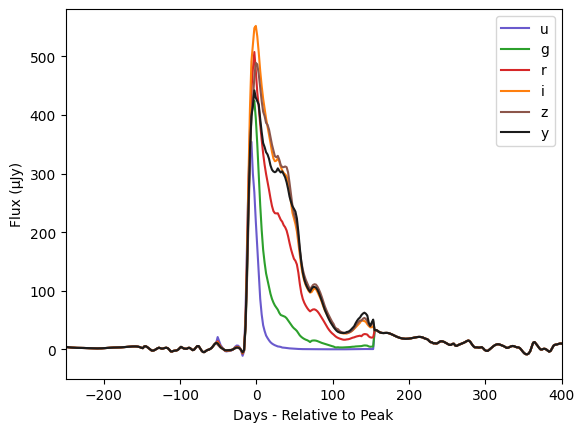

In [ ]:
# 3.5: Using colour difference values to produce simulated data for the other bands using the GP fit of the real observations

#Defining a function to carry out the colour conversions
def colour_convert (input_flux, colour_diff):
    conv_flux = input_flux * 10**(colour_diff/2.5)
    return conv_flux

sim_flux = {}

for val in lsst_filters:
  if main_band_tag == 'r':
    sim_flux[val] = colour_convert(main_band_flux_gp,r_minus[val])
  if main_band_tag == 'g':
    sim_flux[val] = colour_convert(main_band_flux_gp,g_minus[val])


#Plotting the contiguous 6-band lightcurves created using the GP fit and the SNCosmo models
fig2, ax2 = plt.subplots()
for val in lsst_filters:
    ax2.plot(gp_timescale,sim_flux[val],label=val,color = filter_colours[val])
ax2.set_xlabel('Days - Relative to Peak')
ax2.set_ylabel('Flux (μJy)')
plt.xlim(-250,400)
ax2.legend()

**Step Four: Rescaling luminosity of simulated lightcurve**

In [ ]:
# 4.1: Applying reddening to the the fluxes

#Defining a function to carry out the reddening of the flux values to make them accurate to the new redshift
def flux_reddening (flux,fudge):
    flux_lsst = flux * (lsst_lim_flux/ztf_lim_flux) * fudge
    return flux_lsst

lsst_sim_flux = {}
fudge = np.random.normal(loc=1, scale=0.1)

for val in lsst_filters:
    lsst_sim_flux[val] = flux_reddening(sim_flux[val],fudge)

**Step Five: Implementing accurate LSST cadence**

In [ ]:
# 5.1: Defining function to match LSST visit dates to the simulated flux values

def get_match(band_visits, gp_time, gp_flux, err_list, tol=0.5):
    matched = {}

    # Ensure consistent rounding
    band_visits = np.round(band_visits, 4)
    gp_time = np.round(gp_time, 4)

    # Deduplicate visits while preserving errors
    band_visits, unique_idx = np.unique(band_visits, return_index=True)
    err_list = np.array(err_list)[unique_idx]

    for i, visit in enumerate(band_visits):
        # Find the GP point closest in time
        idx = np.argmin(np.abs(gp_time - visit))
        if np.abs(gp_time[idx] - visit) <= tol:
            key = float(np.round(gp_time[idx], 4))
            if key not in matched:
                matched[key] = (gp_flux[idx], err_list[i])

    # Sort keys and build arrays
    times = np.array(sorted(matched.keys()))
    flux = np.array([matched[float(np.round(t, 4))][0] for t in times])
    errs = np.array([matched[float(np.round(t, 4))][1] for t in times])

    return times, flux, errs

In [ ]:
# 5.2: Implementing LSST cadence into lightcurve

#Importing necessary packages
import os
import rubin_sim.maf as maf
import rubin_scheduler.utils as rsUtils

#Choosing new RA, Dec and date (in MJD) for simulated lightcurve.
#In full code these are randomly generated.
sim_obj_ra = 42; sim_obj_dec = -3
sim_date = 63925

#Using baseline from Rubin Survey Simulator
baseline_file = '/content/rubin_sim_data/baseline_v5.0.0_10yrs.db'
name = os.path.basename(baseline_file).replace('.db','')
out_dir = 'temp'
results_db = maf.db.ResultsDb(out_dir=out_dir)
bundle_list = []
metric = maf.metrics.PassMetric(cols=['filter', 'observationStartMJD', 'fiveSigmaDepth', 'visitExposureTime'])

#Setting up slicer for chosen date, RA and Dec
sql = ''
slicer = maf.slicers.UserPointsSlicer(ra=sim_obj_ra, dec=sim_obj_dec)
bundle_list.append(maf.MetricBundle(metric, slicer, sql, run_name=name))
bd = maf.metricBundles.make_bundles_dict_from_list(bundle_list)
bg = maf.metricBundles.MetricBundleGroup(bd, baseline_file, out_dir=out_dir, results_db=results_db)
bg.run_all()

#Producing list of visits with their respective filters
data_slice = bundle_list[0].metric_values[0]
if isinstance(data_slice, dict):
    visit_df = pd.DataFrame([data_slice])
elif isinstance(data_slice, (list, np.ndarray)):
    visit_df = pd.DataFrame(data_slice)
visit_df.sort_values(by='observationStartMJD', inplace=True)
visit_df = visit_df[['observationStartMJD','filter','fiveSigmaDepth']]

visit_list, visit_err, ds_mask = {}, {}, {}

for val in lsst_filters:
  visit_list[val] = []
  ds_mask[val] = visit_df['filter'] == val

for val in lsst_filters:
  visit_list[val] = visit_df.loc[ds_mask[val], 'observationStartMJD'].tolist()
  visit_err[val] = visit_df.loc[ds_mask[val], 'fiveSigmaDepth'].tolist()

#Applying time dilation to lightcurve and shifting peak date accordingly
gp_timescale_shifted = gp_timescale_dilated + sim_date
dilated_peak_idx = np.argmax(main_band_flux_gp)
dilated_peak_time = gp_timescale_shifted[dilated_peak_idx]
sim_date_shift = dilated_peak_time - sim_date
sim_date = sim_date + sim_date_shift

#Using function to generate visit dates and matching fluxes for each of the six bands
#Also generates error values

lsst_visit_list, lsst_visit_flux, lsst_visiter_err = {}, {}, {}

for val in lsst_filters:
  lsst_visit_list[val], lsst_visit_flux[val], lsst_visiter_err[val] = get_match(visit_list[val], gp_timescale_shifted, lsst_sim_flux[val], visit_err[val])

flux_err, mjd_lsst_visit_list = {}, {}

for val in lsst_filters:
  flux_err[val] = ab_to_uJy(lsst_visiter_err[val]) * 0.2

  mjd_lsst_visit_list[val] = lsst_visit_list[val]
  lsst_visit_list[val] = lsst_visit_list[val] - sim_date


u band extinction = [0.15284637]
g band extinction = [0.12141919]
r band extinction = [0.08343498]
i band extinction = [0.06140142]
z band extinction = [0.04792637]
y band extinction = [0.03724261]


(-250.0, 400.0)

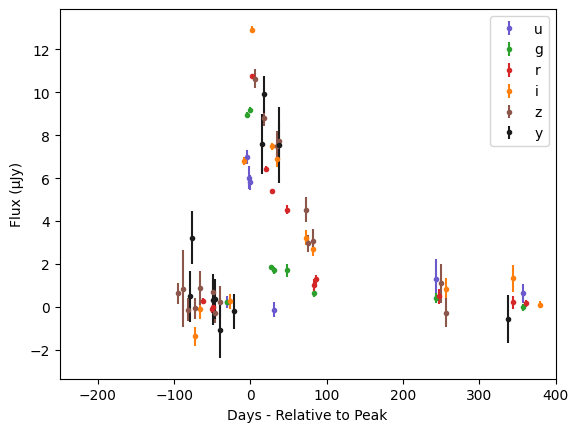

In [ ]:
# 5.3: Applying extinction and random scatter to lightcurve

#Calculating extinction value for simulated object using same method as shown in 1.6
coords = SkyCoord(sim_obj_ra,sim_obj_dec, unit='deg')
SFD = SFDQuery()
ebv = SFD(coords) * 0.86

#Defining function to apply extinction to the flux for a respective band
def flux_extinction (flux, eff_wl):
    A_lambda = fitzpatrick99(eff_wl, ebv * 3.1) #3.1 = Standard Milky Way value
    flux_ext = flux * 10**(-(A_lambda)/2.5)
    return flux_ext, A_lambda

#Effective wavelength for each band - sourced from SVO Filter Profile Service
u_eff_wl = np.array([3641]); g_eff_wl = np.array([4704]); r_eff_wl = np.array([6155])
i_eff_wl = np.array([7504]); z_eff_wl = np.array([8695]); y_eff_wl = np.array([10056])

#Applying extinction to the flux from each band
for val in lsst_filters:
  lsst_visit_flux[val], band_A_lambda = flux_extinction(lsst_visit_flux[val],eval(val+'_eff_wl'))
  print(f'{val} band extinction = {band_A_lambda}')

#Applying random scatter to the lightcurve within measurement uncertainties expected from LSST signal-to-noise. Used to enhance variety in data set.
for val in lsst_filters:
  lsst_visit_flux[val] = np.random.normal(loc = lsst_visit_flux[val], scale = flux_err[val], size = len(lsst_visit_flux[val]))

#Plotting final simulated LSST lightcurve
fig3, ax3 = plt.subplots()
for val in lsst_filters:
    ax3.errorbar(lsst_visit_list[val], lsst_visit_flux[val], yerr = flux_err[val],label=val,color = filter_colours[val], fmt='.', linestyle= None)
ax3.set_xlabel('Days - Relative to Peak')
ax3.set_ylabel('Flux (μJy)')
ax3.legend()
ax3.set_xlim(-250,400)

The same ZTF object can be used to produce multiple simulated LSST lightcurves. The full code has many measures to enhance the variety within the data set whilst remaining grounded in the real ZTF observations. For example, altering the RA, Dec and date of the simulated object can greatly alter the cadence of observations and thus produce a very different final lightcurve. Below are examples of a poor cadence lightcurve and an example of a lightcurve for an object situated within one of the Deep Drilling Fields (DDF).

u band extinction = [0.3083748]
g band extinction = [0.24496897]
r band extinction = [0.16833402]
i band extinction = [0.12388027]
z band extinction = [0.09669372]
y band extinction = [0.07513873]


(-250.0, 400.0)

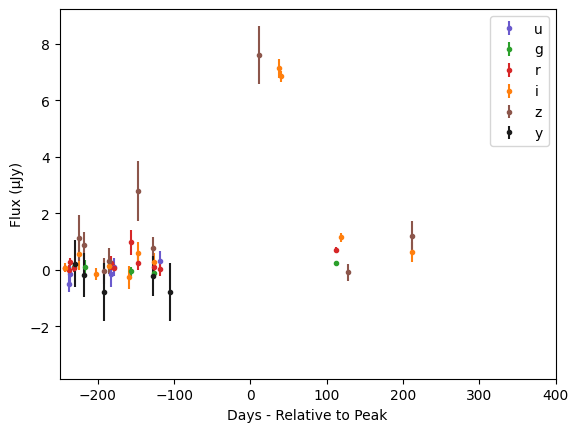

In [ ]:
#Poor cadence example:

# Implementing LSST cadence into lightcurve (second simulated location)

# Choosing new RA, Dec and date (in MJD) for simulated lightcurve
sim_obj_ra = 180; sim_obj_dec = -30
sim_date = 61712

#Using baseline from Rubin Survey Simulator
baseline_file = '/content/rubin_sim_data/baseline_v5.0.0_10yrs.db'
name = os.path.basename(baseline_file).replace('.db','')
out_dir = 'temp'
results_db = maf.db.ResultsDb(out_dir=out_dir)
bundle_list = []
metric = maf.metrics.PassMetric(cols=['filter', 'observationStartMJD', 'fiveSigmaDepth', 'visitExposureTime'])

#Setting up slicer for chosen date, RA and Dec
sql = ''
slicer = maf.slicers.UserPointsSlicer(ra=sim_obj_ra, dec=sim_obj_dec)
bundle_list.append(maf.MetricBundle(metric, slicer, sql, run_name=name))
bd = maf.metricBundles.make_bundles_dict_from_list(bundle_list)
bg = maf.metricBundles.MetricBundleGroup(bd, baseline_file, out_dir=out_dir, results_db=results_db)
bg.run_all()

#Producing list of visits with their respective filters
data_slice = bundle_list[0].metric_values[0]
if isinstance(data_slice, dict):
    visit_df = pd.DataFrame([data_slice])
elif isinstance(data_slice, (list, np.ndarray)):
    visit_df = pd.DataFrame(data_slice)
visit_df.sort_values(by='observationStartMJD', inplace=True)
visit_df = visit_df[['observationStartMJD','filter','fiveSigmaDepth']]

visit_list, visit_err, ds_mask = {}, {}, {}

for val in lsst_filters:
  visit_list[val] = []
  ds_mask[val] = visit_df['filter'] == val

for val in lsst_filters:
  visit_list[val] = visit_df.loc[ds_mask[val], 'observationStartMJD'].tolist()
  visit_err[val] = visit_df.loc[ds_mask[val], 'fiveSigmaDepth'].tolist()

#Applying time dilation to lightcurve and shifting peak date accordingly
gp_timescale_shifted = gp_timescale_dilated + sim_date
dilated_peak_idx = np.argmax(main_band_flux_gp)
dilated_peak_time = gp_timescale_shifted[dilated_peak_idx]
sim_date_shift = dilated_peak_time - sim_date
sim_date = sim_date + sim_date_shift

#Using function to generate visit dates and matching fluxes for each of the six bands
#Also generates error values

pc_lsst_visit_list, pc_lsst_visit_flux, pc_lsst_visiter_err = {}, {}, {}

for val in lsst_filters:
  pc_lsst_visit_list[val], pc_lsst_visit_flux[val], pc_lsst_visiter_err[val] = get_match(visit_list[val], gp_timescale_shifted, lsst_sim_flux[val], visit_err[val])

pc_flux_err, pc_mjd_lsst_visit_list = {}, {}

for val in lsst_filters:
  pc_flux_err[val] = ab_to_uJy(pc_lsst_visiter_err[val]) * 0.2

  pc_mjd_lsst_visit_list[val] = pc_lsst_visit_list[val]
  pc_lsst_visit_list[val] = pc_lsst_visit_list[val] - sim_date

# Applying extinction and random scatter to lightcurve

#Calculating extinction value for simulated object using same method as shown in 1.6
coords = SkyCoord(sim_obj_ra,sim_obj_dec, unit='deg')
SFD = SFDQuery()
ebv = SFD(coords) * 0.86

#Defining function to apply extinction to the flux for a respective band
def flux_extinction (flux, eff_wl):
    A_lambda = fitzpatrick99(eff_wl, ebv * 3.1) #3.1 = Standard Milky Way value
    flux_ext = flux * 10**(-(A_lambda)/2.5)
    return flux_ext, A_lambda

#Effective wavelength for each band - sourced from SVO Filter Profile Service
u_eff_wl = np.array([3641]); g_eff_wl = np.array([4704]); r_eff_wl = np.array([6155])
i_eff_wl = np.array([7504]); z_eff_wl = np.array([8695]); y_eff_wl = np.array([10056])

#Applying extinction to the flux from each band
for val in lsst_filters:
  pc_lsst_visit_flux[val], band_A_lambda = flux_extinction(pc_lsst_visit_flux[val],eval(val+'_eff_wl'))
  print(f'{val} band extinction = {band_A_lambda}')

#Applying random scatter to the lightcurve within measurement uncertainties expected from LSST signal-to-noise. Used to enhance variety in data set.
for val in lsst_filters:
  pc_lsst_visit_flux[val] = np.random.normal(loc = pc_lsst_visit_flux[val], scale = pc_flux_err[val], size = len(pc_lsst_visit_flux[val]))

#Plotting final simulated LSST lightcurve
fig4, ax4 = plt.subplots()
for val in lsst_filters:
    ax4.errorbar(pc_lsst_visit_list[val], pc_lsst_visit_flux[val], yerr = pc_flux_err[val],label=val,color = filter_colours[val], fmt='.', linestyle= None)
ax4.set_xlabel('Days - Relative to Peak')
ax4.set_ylabel('Flux (μJy)')
ax4.legend()
ax4.set_xlim(-250,400)

u band extinction = [0.03431331]
g band extinction = [0.02725805]
r band extinction = [0.01873077]
i band extinction = [0.01378434]
z band extinction = [0.01075925]
y band extinction = [0.00836079]


(-250.0, 400.0)

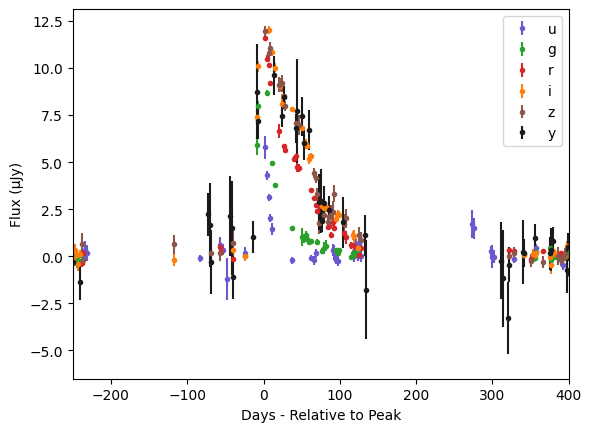

In [ ]:
#Repeat with DDF cadence
#ECDFS - RA : 52.98, Dec : -28.12}

#Selecting simulated RA, Dec and date
sim_obj_ra = 52.98; sim_obj_dec = -28.12
sim_date = 62443

#Using baseline from Rubin Survey Simulator
baseline_file = '/content/rubin_sim_data/baseline_v5.0.0_10yrs.db'
name = os.path.basename(baseline_file).replace('.db','')
out_dir = 'temp'
results_db = maf.db.ResultsDb(out_dir=out_dir)
bundle_list = []
metric = maf.metrics.PassMetric(cols=['filter', 'observationStartMJD', 'fiveSigmaDepth', 'visitExposureTime'])

#Setting up slicer for chosen date, RA and Dec
sql = ''
slicer = maf.slicers.UserPointsSlicer(ra=sim_obj_ra, dec=sim_obj_dec)
bundle_list.append(maf.MetricBundle(metric, slicer, sql, run_name=name))
bd = maf.metricBundles.make_bundles_dict_from_list(bundle_list)
bg = maf.metricBundles.MetricBundleGroup(bd, baseline_file, out_dir=out_dir, results_db=results_db)
bg.run_all()

#Producing list of visits with their respective filters
data_slice = bundle_list[0].metric_values[0]
if isinstance(data_slice, dict):
    visit_df = pd.DataFrame([data_slice])
elif isinstance(data_slice, (list, np.ndarray)):
    visit_df = pd.DataFrame(data_slice)
visit_df.sort_values(by='observationStartMJD', inplace=True)
visit_df = visit_df[['observationStartMJD','filter','fiveSigmaDepth']]

visit_list, visit_err, ds_mask = {}, {}, {}

for val in lsst_filters:
  visit_list[val] = []
  ds_mask[val] = visit_df['filter'] == val

for val in lsst_filters:
  visit_list[val] = visit_df.loc[ds_mask[val], 'observationStartMJD'].tolist()
  visit_err[val] = visit_df.loc[ds_mask[val], 'fiveSigmaDepth'].tolist()

#Applying time dilation to lightcurve and shifting peak date accordingly
gp_timescale_shifted = gp_timescale_dilated + sim_date
dilated_peak_idx = np.argmax(main_band_flux_gp)
dilated_peak_time = gp_timescale_shifted[dilated_peak_idx]
sim_date_shift = dilated_peak_time - sim_date
sim_date = sim_date + sim_date_shift

#Using function to generate visit dates and matching fluxes for each of the six bands
#Also generates error values

ddf_lsst_visit_list, ddf_lsst_visit_flux, ddf_lsst_visiter_err = {}, {}, {}

for val in lsst_filters:
  ddf_lsst_visit_list[val], ddf_lsst_visit_flux[val], ddf_lsst_visiter_err[val] = get_match(visit_list[val], gp_timescale_shifted, lsst_sim_flux[val], visit_err[val])

ddf_flux_err, ddf_mjd_lsst_visit_list = {}, {}

for val in lsst_filters:
  ddf_flux_err[val] = ab_to_uJy(ddf_lsst_visiter_err[val]) * 0.2

  ddf_mjd_lsst_visit_list[val] = ddf_lsst_visit_list[val]
  ddf_lsst_visit_list[val] = ddf_lsst_visit_list[val] - sim_date

# Applying extinction and random scatter to lightcurve

#Calculating extinction value for simulated object using same method as shown in 1.6
coords = SkyCoord(sim_obj_ra,sim_obj_dec, unit='deg')
SFD = SFDQuery()
ebv = SFD(coords) * 0.86

#Defining function to apply extinction to the flux for a respective band
def flux_extinction (flux, eff_wl):
    A_lambda = fitzpatrick99(eff_wl, ebv * 3.1) #3.1 = Standard Milky Way value
    flux_ext = flux * 10**(-(A_lambda)/2.5)
    return flux_ext, A_lambda

#Effective wavelength for each band - sourced from SVO Filter Profile Service
u_eff_wl = np.array([3641]); g_eff_wl = np.array([4704]); r_eff_wl = np.array([6155])
i_eff_wl = np.array([7504]); z_eff_wl = np.array([8695]); y_eff_wl = np.array([10056])

#Applying extinction to the flux from each band
for val in lsst_filters:
  ddf_lsst_visit_flux[val], band_A_lambda = flux_extinction(ddf_lsst_visit_flux[val],eval(val+'_eff_wl'))
  print(f'{val} band extinction = {band_A_lambda}')

#Applying random scatter to the lightcurve within measurement uncertainties expected from LSST signal-to-noise. Used to enhance variety in data set.
for val in lsst_filters:
  ddf_lsst_visit_flux[val] = np.random.normal(loc = ddf_lsst_visit_flux[val], scale = ddf_flux_err[val], size = len(ddf_lsst_visit_flux[val]))

#Plotting final simulated LSST lightcurve
fig5, ax5 = plt.subplots()
for val in lsst_filters:
    ax5.errorbar(ddf_lsst_visit_list[val], ddf_lsst_visit_flux[val], yerr = ddf_flux_err[val],label=val,color = filter_colours[val], fmt='.', linestyle= None)
ax5.set_xlabel('Days - Relative to Peak')
ax5.set_ylabel('Flux (μJy)')
ax5.legend()
ax5.set_xlim(-250,400)

(-250.0, 400.0)

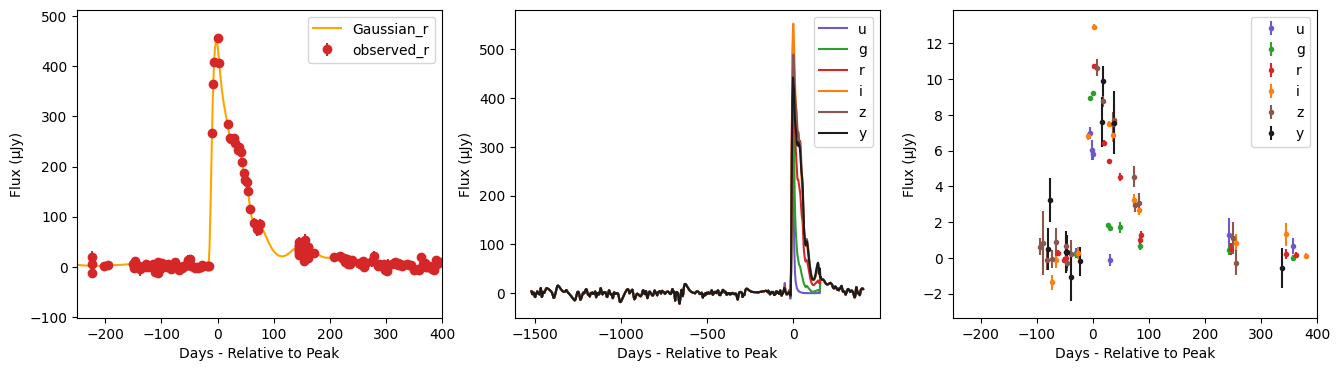

In [ ]:
#Final plot showing three graphs next to each other
#1. ZTF Data w/ GP fit
#2. SNCosmo 6-band contiguous
#3. Final LSST lightcurve

fig, (ax1, ax2, ax3) = plt.subplots(1,3, figsize=(16,4))

ax1.errorbar(main_band_time, main_band_flux, yerr=main_band_error, label='observed_r', color=filter_colours['r'], fmt='o')
ax1.plot(gp_timescale, main_band_flux_gp, label='Gaussian_r', color='orange')
ax1.set_xlabel('Days - Relative to Peak')
ax1.set_ylabel('Flux (μJy)')
ax1.set_xlim(-250,400)
ax1.margins(0.1,0.1)
ax1.legend()

#fig2, ax2 = plt.subplots()
for val in lsst_filters:
    ax2.plot(gp_timescale,sim_flux[val],label=val,color = filter_colours[val])
ax2.set_xlabel('Days - Relative to Peak')
ax2.set_ylabel('Flux (μJy)')
plt.xlim(-250,400)
ax2.legend()

for val in lsst_filters:
    ax3.errorbar(lsst_visit_list[val], lsst_visit_flux[val], yerr = flux_err[val],label=val,color = filter_colours[val], fmt='.', linestyle= None)
ax3.set_xlabel('Days - Relative to Peak')
ax3.set_ylabel('Flux (μJy)')
ax3.legend()
ax3.set_xlim(-250,400)